## Context

This notebook accompanies User Guide section 9 (Tool Catalog).  It enumerates every entry in `governed_agent/tools.py:TOOL_DEFINITIONS`, runs a small subset of them through the `GovernedToolGateway` against the iris dataset, and renders a `(tool, gate)` heatmap showing which gates passed and which blocked.  Reading this notebook gives you the working surface every later tutorial that calls a tool relies on.

In [1]:
# Phase 3a preamble: bootstrap runtime + load shared helpers
import sys
import os
import glob
import warnings
warnings.filterwarnings('ignore')
for _p in glob.glob(
        '/home/asudjianto/cluster/spark-venv/lib/python*/site-packages'):
    if _p not in sys.path:
        sys.path.insert(0, _p)
_REPO = os.path.expanduser('~/jupyterlab/kg-memory')
if _REPO not in sys.path:
    sys.path.insert(0, _REPO)

from user_guide_tutorials.notebooks import _helpers_phase1 as h1
h1.bootstrap_runtime()
from user_guide_tutorials.notebooks import _shared as ug
import torch
DEVICE = ug.DEVICE
print(f'Device: {DEVICE}, CUDA available: {torch.cuda.is_available()}')

Device: cuda, CUDA available: True


### Concept: a tool is a JSON-schema'd Python function

Every entry in `TOOL_DEFINITIONS` has three fields the gateway cares about: a `name` the dispatcher branches on, an `input_schema` the schema gate validates against, and a `description` that the policy gate and the LLM-side tool description both consume.  The handler in `execute_tool(name, args, state)` returns a tuple of `(display_string, raw_dict)`.  The `display_string` is a human-readable summary that surfaces in transcripts; the `raw_dict` is pure-Python and is what Tier-1 extraction in section 7 SHA-256-hashes for the audit chain.

The triple-gate pipeline in section 16 wraps every call in three checks executed in order: schema validation, the policy engine, and a hard plausibility check that scores `(context, should_call, tool_name)` on the GMS manifold.  The first two gates fail closed; the plausibility gate fails open when the relation triple is not in the store, which is what permits unfamiliar context strings in early tutorials.  All 15 tools share the same uniform pipeline, which is what makes the downstream verifier and tracer composable.

Below we (1) print the schema of every tool, (2) call a five-tool subset end-to-end on iris, and (3) render the per-call gate verdict as a heatmap.

In [ ]:
from knowlytix.harness.governance.tools import TOOL_DEFINITIONS
from knowlytix.harness.governance.session import SessionState
from knowlytix.harness.governance.governed_gateway import GovernedToolGateway

store = ug.load_ds_practices_store()
session = SessionState()
gateway = GovernedToolGateway(
    session=session,
    store=store,
    theta_plausibility=1.5,
    tool_schemas=TOOL_DEFINITIONS,
    device=str(DEVICE),
)
print(f'Catalog size: {len(TOOL_DEFINITIONS)} tools')

In [3]:
# Print one summary row per tool: name, required args, description
rows = []
for spec in TOOL_DEFINITIONS:
    schema = spec.get('input_schema', {})
    required = schema.get('required', [])
    rows.append((
        spec['name'],
        ','.join(required) if required else '-',
        spec['description'].split('.')[0][:70],
    ))
header = f"{'tool':<22s} {'required':<32s} description"
print(header)
print('-' * len(header))
for name, req, desc in rows:
    print(f'{name:<22s} {req:<32s} {desc}')

tool                   required                         description
-------------------------------------------------------------------
load_dataset           name                             Load a dataset via sklearn
data_summary           dataset                          Summary statistics: df
eda_correlation        dataset                          Compute correlation matrix between features
preprocess_data        dataset                          Impute + scale + encode via sklearn Pipeline
feature_select         dataset,method                   Feature selection via SelectKBest or tree-based importance
train_model            dataset,model_type,model_name    Fit an sklearn estimator and compute train/test metrics
predict                dataset,model_name               Generate predictions on the test set for a trained model
leaderboard            dataset                          Compare all trained models for a dataset, ranked by metric
diagnose_robustness    dataset,model_name     

In [4]:
# Call a five-tool subset through the gateway end-to-end on iris.
# Order matters: load -> summary -> correlation -> train -> predict.
plan = [
    ('load_dataset',
     {'name': 'iris', 'builtin': 'iris'},
     'data_loading'),
    ('data_summary',
     {'dataset': 'iris'},
     'exploratory_data_analysis'),
    ('eda_correlation',
     {'dataset': 'iris', 'method': 'pearson'},
     'exploratory_data_analysis'),
    ('train_model',
     {'dataset': 'iris',
      'model_type': 'RandomForestClassifier',
      'model_name': 'rf_iris',
      'params': {'n_estimators': 20, 'random_state': 0}},
     'model_training'),
    ('predict',
     {'dataset': 'iris', 'model_name': 'rf_iris'},
     'evaluation'),
]
critical_tool_results = []
for tool, args, ctx in plan:
    r = gateway.execute(tool, args, context=ctx)
    critical_tool_results.append((tool, r))
    flag = 'OK ' if not r.blocked else 'BLK'
    print(f'{flag}  {tool:18s} {r.execution_time_ms:7.1f} ms'
          f'  gates={r.gate_results}')

OK   load_dataset           4.2 ms  gates={'schema': True, 'policy': True, 'plausibility': True, 'fault_injection': True}
OK   data_summary           4.7 ms  gates={'schema': True, 'policy': True, 'plausibility': True, 'fault_injection': True}
OK   eda_correlation        0.9 ms  gates={'schema': True, 'policy': True, 'plausibility': True, 'fault_injection': True}
OK   train_model           14.1 ms  gates={'schema': True, 'policy': True, 'plausibility': True, 'fault_injection': True}
OK   predict                1.0 ms  gates={'schema': True, 'policy': True, 'plausibility': True, 'fault_injection': True}


In [5]:
# Inspect one raw dict so the reader can see Tier-1's input.
_, train_result = critical_tool_results[3]
metrics = train_result.raw.get('metrics', {})
print('train_model raw["metrics"]:')
for k, v in metrics.items():
    print(f'  {k:18s} {v}')

train_model raw["metrics"]:
  train_accuracy     1.0
  train_f1_macro     1.0
  train_auc_ovr      1.0
  test_accuracy      1.0
  test_f1_macro      1.0
  test_auc_ovr       1.0
  train_test_gap     0.0


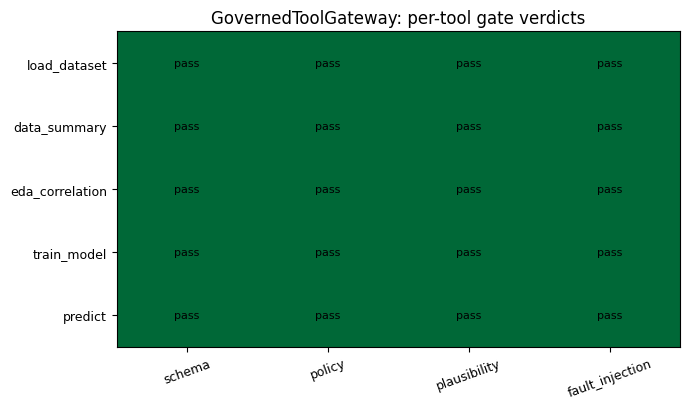

In [6]:
# Visualization: heatmap of (tool, gate) outcomes.
# Rows are tools called; columns are gate identities.
# Cell values: 1 = passed, 0 = blocked, -1 = not reached.
import matplotlib.pyplot as plt
import numpy as np

gate_names = ['schema', 'policy', 'plausibility', 'fault_injection']
tool_names = [t for t, _ in critical_tool_results]
matrix = np.full((len(tool_names), len(gate_names)), -1, dtype=float)
for i, (_, r) in enumerate(critical_tool_results):
    for j, g in enumerate(gate_names):
        if g in r.gate_results:
            matrix[i, j] = 1.0 if r.gate_results[g] else 0.0

fig, ax = plt.subplots(figsize=(7, 0.6 * len(tool_names) + 1.2))
im = ax.imshow(matrix, cmap='RdYlGn', vmin=-1, vmax=1, aspect='auto')
ax.set_xticks(range(len(gate_names)))
ax.set_xticklabels(gate_names, rotation=20, fontsize=9)
ax.set_yticks(range(len(tool_names)))
ax.set_yticklabels(tool_names, fontsize=9)
for i in range(len(tool_names)):
    for j in range(len(gate_names)):
        v = matrix[i, j]
        label = 'pass' if v == 1 else ('block' if v == 0 else 'n/a')
        ax.text(j, i, label, ha='center', va='center', fontsize=8, color='black')
ax.set_title('GovernedToolGateway: per-tool gate verdicts')
fig.tight_layout()
plt.show()

### Exercises

1. Construct an args dict for `load_dataset` that omits the required `name` key.  Run it through the gateway and confirm the schema gate blocks before the policy gate fires.  Read `result.gate_results` to verify.
2. Add a fault-injection profile via `gateway.add_fault_profile(...)` that targets `train_model` with `error_rate=1.0` and rerun the plan.  Which gate now records the block in `gate_results`?
3. Pick one tool you have never read.  Print its full JSON schema (`input_schema`) and identify which keys are required versus optional, and which optional keys carry a default in the handler.

### What you should now be able to do

- Enumerate every tool in `TOOL_DEFINITIONS` and read the required fields from its `input_schema`.
- Wire a `GovernedToolGateway` against a fixture store and the catalog in three lines.
- Execute a multi-step plan and read the per-call `gate_results` to determine which gates fired.
- Recognise that the `(display_string, raw_dict)` contract is what makes the audit chain reproducible.

### Cross-references

- USER_GUIDE.md section 9 (Tool Catalog)
- USER_GUIDE.md section 16 (Governed Tool Gateway) for the three-gate semantics demoed here.
- `governed_agent/tools.py:TOOL_DEFINITIONS` and `governed_agent/tools.py:execute_tool`
- `governed_agent/governed_gateway.py:GovernedToolGateway.execute`
- `gms_agent_builder_ext/chapters/ch03.tex` for the tool catalog as a chapter.

In [7]:
# Final assertions: the catalog has at least 10 tools and
# every critical tool in the demo plan ran without a block.
assert len(TOOL_DEFINITIONS) >= 10, (
    f'expected >= 10 tools, got {len(TOOL_DEFINITIONS)}'
)
blocked = [(t, r.reason) for t, r in critical_tool_results if r.blocked]
assert all(not r.blocked for _, r in critical_tool_results), (
    f'critical tool blocked: {blocked}'
)
print(f'OK: {len(TOOL_DEFINITIONS)} tools registered, '
      f'{len(critical_tool_results)} critical tools passed.')

OK: 15 tools registered, 5 critical tools passed.
